# LAB 1 — PHẦN 1, BÀI 2: KHẢO SÁT VÀ TIỀN XỬ LÝ DỮ LIỆU BANK MARKETING (TRANG 28–29)

Notebook này thực hiện đầy đủ **6 bước tiền xử lý cơ bản** theo phần *Hướng dẫn chung* (Tài liệu LAB1, trang 13–15) cho bài toán **Bank Marketing** (trang 28–29) trên cả hai phạm vi:

- **Phần A**: Bảng mẫu **16 dòng** trích trực tiếp từ Tài liệu LAB1 trang 28–29 (`Job`, `Marial`, `Education`, `Default`, `Loan`, `Duration`, `Cons.price.idx`, `Subscribe`).
- **Phần B**: Tập dữ liệu đầy đủ **`Dataset/bank/bank.csv`** (4,521 dòng, 17 thuộc tính, phân tách bằng dấu `;`).

**Nội dung 6 bước tiền xử lý cho cả Phần A và Phần B:**
1. Khảo sát dữ liệu (`head`, `info`, `describe`) và phân loại thuộc tính (`Nominal`, `Ordinal`, `Binary symmetric/asymmetric`, `Interval-scaled`, `Ratio-scaled`).
2. Kiểm tra và xử lý dữ liệu bị thiếu (`NaN`, giá trị ẩn `'unknown'`, và giá trị đặc biệt `pdays == -1`).
3. Khử nhiễu thuộc tính số bằng kỹ thuật **Binning** và **Smoothing** (làm trơn theo trung bình giỏ) + trực quan hóa so sánh trước/sau.
4. Rời rạc hóa dữ liệu thuộc tính số theo **khoảng giá trị** và theo **nhãn khái niệm** (`Short`/`Medium`/`Long`, `Youth`/`Adult`/`Middle-aged`/`Senior`).
5. Mã hóa **One-hot Encoding** cho các thuộc tính định tính (`pd.get_dummies(..., dtype=int)`).
6. Chuẩn hóa **Min-Max Normalization** các thuộc tính số về đoạn `[0, 1]` theo công thức trang 15 và kiểm chứng với `MinMaxScaler`.


In [1]:
import os
import sys
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

# Thông tin sinh viên
STUDENT_NAME = "Nguyễn Phạm Bảo Khanh"
MSSV = "6451071033"

# Cấu hình hiển thị và biểu đồ
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.unicode_minus"] = False

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1rv5SiO5zFlU-cyEXul09OpCvTXrdjG1m?usp=sharing"


def get_dataset_path(relative_path: str) -> Path:
    """Tìm tệp dữ liệu cục bộ, trên Google Drive (Colab), hoặc tải qua gdown."""
    local_path = Path("Dataset") / relative_path
    if local_path.exists():
        print(f"[Dataset] Đọc từ thư mục cục bộ: {local_path}")
        return local_path

    if "google.colab" in sys.modules:
        from google.colab import drive
        drive.mount("/content/drive", force_remount=False)
        colab_path = Path("/content/drive/MyDrive/Dataset") / relative_path
        if colab_path.exists():
            print(f"[Dataset] Đọc từ Google Drive (Colab): {colab_path}")
            return colab_path

    print("[Dataset] Đang tải bộ dữ liệu từ Google Drive bằng gdown...")
    os.makedirs("Dataset", exist_ok=True)
    subprocess.run(
        ["gdown", "--folder", DRIVE_FOLDER_URL, "-O", "Dataset"],
        check=True,
    )
    if local_path.exists():
        print(f"[Dataset] Đã tải về: {local_path}")
        return local_path

    matches = list(Path("Dataset").rglob(Path(relative_path).name))
    if matches:
        print(f"[Dataset] Tìm thấy tại: {matches[0]}")
        return matches[0]
    raise FileNotFoundError(f"Không tìm thấy tệp dữ liệu: {local_path}")


print(f"{STUDENT_NAME} - {MSSV}")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | numpy: {np.__version__} | seaborn: {sns.__version__}")


Nguyễn Phạm Bảo Khanh - 6451071033
Python: 3.15.0 | pandas: 3.1.1 | numpy: 2.5.5 | seaborn: 0.13.2


---
## PHẦN A: KHẢO SÁT VÀ TIỀN XỬ LÝ BẢNG MẪU 16 DÒNG (PDF TRANG 28–29)

Bảng dữ liệu mẫu gồm **16 quan sát** và **8 thuộc tính** trích từ tập `bank-additional` trong Tài liệu LAB1 (trang 28–29). Lưu ý giữ nguyên chính xác các đặc điểm nguyên bản của bảng PDF:
- Tên cột `Marial` (viết thiếu chữ `t` trong tài liệu gốc) và giá trị `'Retired'` viết hoa chữ đầu ở dòng cuối.
- Dòng thứ 7 (`index=6`, `Job='management'`) bị khuyết giá trị `Cons.price.idx` (`np.nan`).
- Dòng thứ 8 (`index=7`, `Job='unemployed'`) bị khuyết giá trị `Marial` (`np.nan`).
- Cột `Default` có 5 dòng chứa giá trị `'unknown'`.


### Phần A — Bước 1: Tạo bảng mẫu 16 dòng, khảo sát (`head`, `info`, `describe`) và phân loại thuộc tính


In [2]:
print(f"{STUDENT_NAME} - {MSSV}")

columns_a = [
    "Job", "Marial", "Education", "Default",
    "Loan", "Duration", "Cons.price.idx", "Subscribe"
]

rows_a = [
    ["housemaid",     "Married",  "basic.4y",            "no",      "no",  261,  93.994, "no"],
    ["services",      "Married",  "high.school",         "unknown", "no",  149,  93.994, "no"],
    ["blue-collar",   "Divorced", "basic.4y",            "unknown", "no",  1575, 93.994, "yes"],
    ["admin.",        "Single",   "high.school",         "no",      "no",  338,  93.994, "no"],
    ["blue-collar",   "Single",   "basic.9y",            "no",      "no",  179,  93.994, "no"],
    ["services",      "Married",  "high.school",         "no",      "no",  1030, 93.994, "yes"],
    ["management",    "Married",  "high.school",         "unknown", "no",  149,  np.nan, "no"],
    ["unemployed",    np.nan,     "university.degree",   "unknown", "no",  424,  93.994, "no"],
    ["technician",    "Married",  "professional.course", "no",      "no",  1623, 93.994, "yes"],
    ["services",      "Divorced", "high.school",         "unknown", "no",  568,  93.994, "no"],
    ["blue-collar",   "Married",  "high.school",         "no",      "no",  1297, 93.994, "yes"],
    ["self-employed", "Married",  "basic.9y",            "no",      "no",  376,  93.918, "no"],
    ["entrepreneur",  "Married",  "professional.course", "no",      "yes", 576,  93.994, "no"],
    ["services",      "Single",   "high.school",         "no",      "no",  1059, 93.2,   "yes"],
    ["technician",    "Married",  "basic.9y",            "no",      "no",  705,  93.2,   "yes"],
    ["Retired",       "Married",  "high.school",         "no",      "no",  532,  93.2,   "no"],
]

df_a_raw = pd.DataFrame(rows_a, columns=columns_a)
print("Kích thước bảng mẫu Phần A:", df_a_raw.shape)
print("\n--- Toàn bộ 16 dòng bảng mẫu (head(16)) ---")
display(df_a_raw)

print("\n--- Thông tin kiểu dữ liệu (info) ---")
df_a_raw.info()

print("\n--- Thống kê mô tả thuộc tính số (describe) ---")
display(df_a_raw.describe())

print("\n--- Thống kê mô tả thuộc tính định tính ---")
display(df_a_raw.describe(exclude=[np.number]))

print("\nPhân bố biến mục tiêu Subscribe:")
print(df_a_raw["Subscribe"].value_counts())


Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước bảng mẫu Phần A: (16, 8)

--- Toàn bộ 16 dòng bảng mẫu (head(16)) ---


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
0,housemaid,Married,basic.4y,no,no,261,93.994,no
1,services,Married,high.school,unknown,no,149,93.994,no
2,blue-collar,Divorced,basic.4y,unknown,no,1575,93.994,yes
3,admin.,Single,high.school,no,no,338,93.994,no
4,blue-collar,Single,basic.9y,no,no,179,93.994,no
5,services,Married,high.school,no,no,1030,93.994,yes
6,management,Married,high.school,unknown,no,149,NaN,no
7,unemployed,NaN,university.degree,unknown,no,424,93.994,no
8,technician,Married,professional.course,no,no,1623,93.994,yes
9,services,Divorced,high.school,unknown,no,568,93.994,no



--- Thông tin kiểu dữ liệu (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 16 entries, 0 to 15
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Job             16 non-null     str    
 1   Marial          15 non-null     str    
 2   Education       16 non-null     str    
 3   Default         16 non-null     str    
 4   Loan            16 non-null     str    
 5   Duration        16 non-null     int64  
 6   Cons.price.idx  15 non-null     float64
 7   Subscribe       16 non-null     str    
dtypes: float64(1), int64(1), str(6)
memory usage: 1.7 KB

--- Thống kê mô tả thuộc tính số (describe) ---


,Duration,Cons.price.idx
count,16.000000,15.000000
mean,677.562500,93.830133
std,493.173258,0.326704
min,149.000000,93.200000
25%,318.750000,93.956000
50%,550.000000,93.994000
75%,1037.250000,93.994000
max,1623.000000,93.994000



--- Thống kê mô tả thuộc tính định tính ---


,Job,Marial,Education,Default,Loan,Subscribe
count,16,15,16,16,16,16
unique,10,3,5,2,2,2
top,services,Married,high.school,no,no,no
freq,4,10,8,11,15,10



Phân bố biến mục tiêu Subscribe:
Subscribe
no     10
yes     6
Name: count, dtype: int64


#### Phân loại 8 thuộc tính trong bảng mẫu Phần A (theo lý thuyết PDF trang 1–3)

| Thuộc tính | Nhóm lớn | Phân loại chi tiết | Giải thích |
|---|---|---|---|
| `Job` | Qualitative (Định tính) | **Nominal** | Tên nghề nghiệp (`housemaid`, `services`, `blue-collar`, ...), không có thứ tự tự nhiên; chỉ đo xu hướng tập trung bằng `mode`. |
| `Marial` | Qualitative (Định tính) | **Nominal** | Tình trạng hôn nhân (`Married`, `Single`, `Divorced`), không có thứ bậc; có 1 ô khuyết (`NaN`) tại dòng `index=7`. |
| `Education` | Qualitative (Định tính) | **Ordinal** | Trình độ học vấn có thứ tự tăng dần (`basic.4y` < `basic.9y` < `high.school` < `professional.course` < `university.degree`), nhưng không đo được khoảng cách chính xác giữa các bậc. |
| `Default` | Qualitative (Định tính) | **Binary asymmetric** *(kèm `'unknown'`)* | Có tín dụng mặc định hay chưa (`no` / `unknown` trong mẫu; trạng thái `yes` hiếm và quan trọng hơn về rủi ro). |
| `Loan` | Qualitative (Định tính) | **Binary asymmetric** | Có khoản vay cá nhân hay không (`no`: 15, `yes`: 1); hai trạng thái không mang trọng lượng ngang nhau. |
| `Duration` | Quantitative (Định lượng) | **Ratio-scaled** | Thời lượng cuộc gọi liên hệ cuối (giây), có điểm `0` thật sự (`0s` = không có cuộc gọi), phép chia/nhân có ý nghĩa. |
| `Cons.price.idx` | Quantitative (Định lượng) | **Interval-scaled** | Chỉ số giá tiêu dùng (CPI), đo biến động giá so với kỳ gốc nên không có điểm `0` tuyệt đối "không có giá cả"; chênh lệch giữa các mốc có ý nghĩa; có 1 ô khuyết (`NaN`) tại dòng `index=6`. |
| `Subscribe` | Qualitative (Định tính) | **Binary asymmetric** *(Thuộc tính quyết định)* | Khách hàng đăng ký tiền gửi có kỳ hạn hay không (`yes`: 6, `no`: 10), là nhãn mục tiêu của bài toán phân lớp. |


### Phần A — Bước 2: Kiểm tra và xử lý dữ liệu bị thiếu (`NaN` và `'unknown'`)

Theo hướng dẫn trang 13–14:
- Thuộc tính số bị thiếu (`Cons.price.idx` ở dòng `index=6`): tính toán và đối chiếu **trung bình (mean)**, **trung vị (median)** toàn cục và theo nhóm thuộc tính quyết định `Subscribe`. Do `Cons.price.idx` có bậc thang lệch xuống `93.2` ở cuối bảng trong khi 11/15 dòng đầu giữ mức `93.994`, **trung vị (`93.994`)** phản ánh sát giá trị đặc trưng của phân khúc này hơn (và khớp luôn với trung vị nhóm `Subscribe='no'`).
- Thuộc tính định tính bị thiếu tường minh (`Marial` ở dòng `index=7`): điền bằng giá trị xuất hiện nhiều nhất (**mode** = `'Married'`).
- Thuộc tính chứa nhãn `'unknown'` (`Default`: 5/16 dòng = `31.25%`): đối chiếu hai phương án theo PDF trang 14 — **(1) giữ `'unknown'` như một loại/nhãn riêng** để bảo toàn tín hiệu hành vi của nhóm khách hàng không khai báo (áp dụng cho `df_a_clean`), và **(2) điền bằng mode (`'no'`)** trên bản sao đối chiếu.


In [3]:
print(f"{STUDENT_NAME} - {MSSV}")

print("--- Thống kê giá trị NaN ban đầu ---")
print(df_a_raw.isnull().sum())

print("\n--- Thống kê giá trị 'unknown' ban đầu ---")
for col in df_a_raw.select_dtypes(exclude=[np.number]).columns:
    unk_cnt = (df_a_raw[col] == "unknown").sum()
    if unk_cnt > 0:
        print(f"Cột {col}: {unk_cnt}/{len(df_a_raw)} dòng ({unk_cnt/len(df_a_raw)*100:.2f}%) là 'unknown'")

cpi_mean = df_a_raw["Cons.price.idx"].mean()
cpi_median = df_a_raw["Cons.price.idx"].median()
cpi_group = df_a_raw.groupby("Subscribe")["Cons.price.idx"].agg(["mean", "median"])

print(f"\nCons.price.idx — Mean toàn cục: {cpi_mean:.4f} | Median toàn cục: {cpi_median:.4f}")
print("Cons.price.idx theo nhóm Subscribe:")
display(cpi_group)

marial_mode = df_a_raw["Marial"].mode()[0]
default_known_mode = df_a_raw.loc[df_a_raw["Default"] != "unknown", "Default"].mode()[0]
print(f"Mode của Marial: {marial_mode!r}")
print(f"Mode các giá trị đã biết của Default: {default_known_mode!r}")

# Áp dụng xử lý trên df_a_clean
df_a_clean = df_a_raw.copy()
df_a_clean["Cons.price.idx"] = df_a_clean["Cons.price.idx"].fillna(cpi_median)
df_a_clean["Marial"] = df_a_clean["Marial"].fillna(marial_mode)

# Bản sao minh họa nếu thay thế 'unknown' trong Default bằng mode ('no')
df_a_default_mode = df_a_clean.copy()
df_a_default_mode["Default"] = df_a_default_mode["Default"].replace("unknown", default_known_mode)

print("\n--- Đối chiếu các dòng đã điền thiếu (index 6 và 7) ---")
print("Trước xử lý:")
display(df_a_raw.loc[[6, 7]])
print("Sau xử lý (df_a_clean — giữ 'unknown' trong Default như một nhãn riêng):")
display(df_a_clean.loc[[6, 7]])

print("\nKiểm tra lại số lượng NaN sau xử lý:")
print(df_a_clean.isnull().sum().to_dict())
print("Phân bố Default trong df_a_clean:", df_a_clean["Default"].value_counts().to_dict())
print("Phân bố Default trong bản đối chiếu điền mode:", df_a_default_mode["Default"].value_counts().to_dict())


Nguyễn Phạm Bảo Khanh - 6451071033
--- Thống kê giá trị NaN ban đầu ---
Job               0
Marial            1
Education         0
Default           0
Loan              0
Duration          0
Cons.price.idx    1
Subscribe         0
dtype: int64

--- Thống kê giá trị 'unknown' ban đầu ---
Cột Default: 5/16 dòng (31.25%) là 'unknown'

Cons.price.idx — Mean toàn cục: 93.8301 | Median toàn cục: 93.9940
Cons.price.idx theo nhóm Subscribe:


,mean,median
Subscribe,,
no,93.897333,93.994
yes,93.729333,93.994


Mode của Marial: 'Married'
Mode các giá trị đã biết của Default: 'no'

--- Đối chiếu các dòng đã điền thiếu (index 6 và 7) ---
Trước xử lý:


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
6,management,Married,high.school,unknown,no,149,NaN,no
7,unemployed,NaN,university.degree,unknown,no,424,93.994,no


Sau xử lý (df_a_clean — giữ 'unknown' trong Default như một nhãn riêng):


,Job,Marial,Education,Default,Loan,Duration,Cons.price.idx,Subscribe
6,management,Married,high.school,unknown,no,149,93.994,no
7,unemployed,Married,university.degree,unknown,no,424,93.994,no



Kiểm tra lại số lượng NaN sau xử lý:
{'Job': 0, 'Marial': 0, 'Education': 0, 'Default': 0, 'Loan': 0, 'Duration': 0, 'Cons.price.idx': 0, 'Subscribe': 0}
Phân bố Default trong df_a_clean: {'no': 11, 'unknown': 5}
Phân bố Default trong bản đối chiếu điền mode: {'no': 16}


### Phần A — Bước 3: Khử nhiễu thuộc tính số (`Duration`) bằng kỹ thuật Binning và Smoothing

Theo hướng dẫn trang 14:
- Thuộc tính `Duration` có giá trị nhỏ nhất là `149` giây và lớn nhất là `1623` giây.
- Chọn biên `[0, 1800]` với độ rộng mỗi giỏ là `450` giây để chia thành 4 giỏ đều độ rộng (**Equal-width Binning**): `(0, 450]`, `(450, 900]`, `(900, 1350]`, `(1350, 1800]`.
- Thực hiện **Smoothing by bin mean**: thay giá trị `Duration` trong mỗi giỏ bằng trung bình của chính giỏ đó. Đồng thời đối chiếu với chia giỏ đều tần suất (**Equal-frequency Binning**, `q=4`).


Nguyễn Phạm Bảo Khanh - 6451071033
--- Bảng tóm tắt Equal-width Binning & Smoothing (Duration) ---


,Duration_ew_bin,So_luong,Min,Max,Mean_Smoothing
0,"(0, 450]",7,149,424,268.000000
1,"(450, 900]",4,532,705,595.250000
2,"(900, 1350]",3,1030,1297,1128.666667
3,"(1350, 1800]",2,1575,1623,1599.000000


Độ lệch chuẩn Duration trước làm trơn: 493.17 | Sau Equal-width smoothing: 483.73 | Sau Equal-frequency smoothing: 467.03


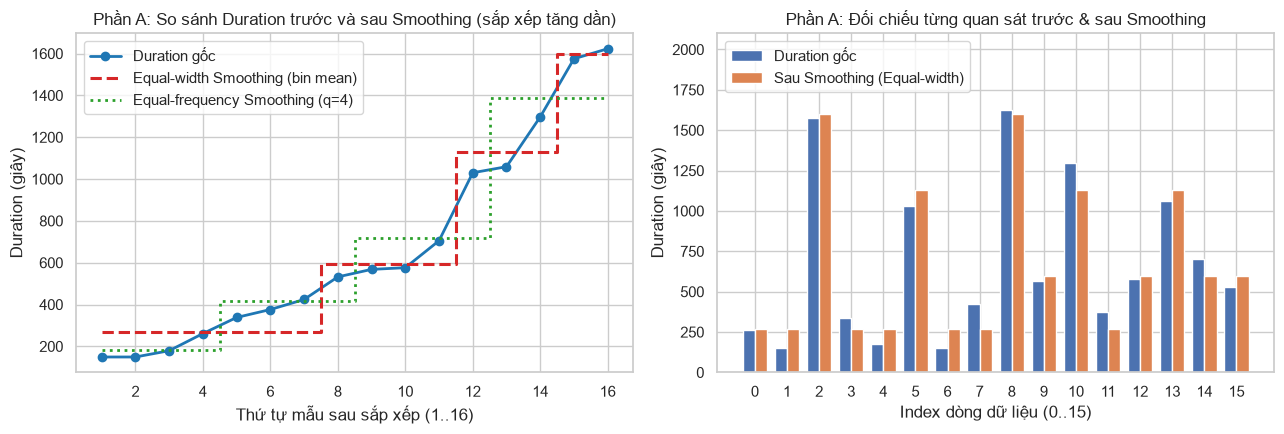

In [4]:
print(f"{STUDENT_NAME} - {MSSV}")

bins_a = [0, 450, 900, 1350, 1800]
df_a_bin = df_a_clean[["Duration", "Subscribe"]].copy()
df_a_bin["Duration_ew_bin"] = pd.cut(df_a_bin["Duration"], bins=bins_a)
df_a_bin["Duration_ew_smoothed"] = (
    df_a_bin.groupby("Duration_ew_bin", observed=False)["Duration"]
    .transform("mean")
    .round(2)
)

df_a_bin["Duration_ef_bin"] = pd.qcut(df_a_bin["Duration"], q=4)
df_a_bin["Duration_ef_smoothed"] = (
    df_a_bin.groupby("Duration_ef_bin", observed=False)["Duration"]
    .transform("mean")
    .round(2)
)

ew_summary = (
    df_a_bin.groupby("Duration_ew_bin", observed=False)["Duration"]
    .agg(So_luong="count", Min="min", Max="max", Mean_Smoothing="mean")
    .reset_index()
)
print("--- Bảng tóm tắt Equal-width Binning & Smoothing (Duration) ---")
display(ew_summary)

print(
    f"Độ lệch chuẩn Duration trước làm trơn: {df_a_bin['Duration'].std():.2f} | "
    f"Sau Equal-width smoothing: {df_a_bin['Duration_ew_smoothed'].std():.2f} | "
    f"Sau Equal-frequency smoothing: {df_a_bin['Duration_ef_smoothed'].std():.2f}"
)

# Lưu cột Duration_smoothed vào df_a_clean để tham chiếu
df_a_clean["Duration_smoothed"] = df_a_bin["Duration_ew_smoothed"]

# Trực quan hóa so sánh trước và sau làm trơn
df_sorted_a = df_a_bin.sort_values("Duration").reset_index(drop=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(
    df_sorted_a.index + 1, df_sorted_a["Duration"],
    marker="o", linewidth=2, label="Duration gốc", color="#1f77b4"
)
axes[0].step(
    df_sorted_a.index + 1, df_sorted_a["Duration_ew_smoothed"],
    where="mid", linestyle="--", linewidth=2.2, label="Equal-width Smoothing (bin mean)", color="#d62728"
)
axes[0].step(
    df_sorted_a.index + 1, df_sorted_a["Duration_ef_smoothed"],
    where="mid", linestyle=":", linewidth=2.0, label="Equal-frequency Smoothing (q=4)", color="#2ca02c"
)
axes[0].set_title("Phần A: So sánh Duration trước và sau Smoothing (sắp xếp tăng dần)")
axes[0].set_xlabel("Thứ tự mẫu sau sắp xếp (1..16)")
axes[0].set_ylabel("Duration (giây)")
axes[0].legend()

x_pos = np.arange(len(df_a_bin))
width = 0.38
axes[1].bar(x_pos - width / 2, df_a_bin["Duration"], width, label="Duration gốc", color="#4c72b0")
axes[1].bar(x_pos + width / 2, df_a_bin["Duration_ew_smoothed"], width, label="Sau Smoothing (Equal-width)", color="#dd8452")
axes[1].set_title("Phần A: Đối chiếu từng quan sát trước & sau Smoothing")
axes[1].set_xlabel("Index dòng dữ liệu (0..15)")
axes[1].set_ylabel("Duration (giây)")
axes[1].set_xticks(x_pos)
axes[1].set_ylim(0, 2100)
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()


**Nhận xét Bước 3 (Phần A):** Kỹ thuật Binning và làm trơn theo trung bình giỏ gom các giá trị dao động trong từng khoảng về một giá trị đại diện ổn định (ví dụ nhóm `(0, 450]` gồm 7 mẫu dao động từ `149s` đến `424s` được làm trơn về đúng giá trị trung bình `268.00s`), giúp giảm nhiễu cục bộ và thu gọn độ lệch chuẩn từ `493.17s` xuống `483.73s` (Equal-width) hoặc `467.03s` (Equal-frequency).


### Phần A — Bước 4: Rời rạc hóa thuộc tính số (`Duration`) theo khoảng giá trị và nhãn khái niệm

Rời rạc hóa `Duration` (đơn vị giây) thành 3 mức thời lượng cuộc gọi có ý nghĩa nghiệp vụ:
- **Theo khoảng giá trị**: `(0, 300]`, `(300, 900]`, `(900, 1800]`
- **Theo nhãn khái niệm**: `Short` (≤ 5 phút), `Medium` (5–15 phút), `Long` (> 15 phút)


Nguyễn Phạm Bảo Khanh - 6451071033
--- Kết quả rời rạc hóa Duration (16 dòng) ---


,Job,Duration,Duration_interval,Duration_label,Subscribe
0,housemaid,261,"(0, 300]",Short,no
1,services,149,"(0, 300]",Short,no
2,blue-collar,1575,"(900, 1800]",Long,yes
3,admin.,338,"(300, 900]",Medium,no
4,blue-collar,179,"(0, 300]",Short,no
5,services,1030,"(900, 1800]",Long,yes
6,management,149,"(0, 300]",Short,no
7,unemployed,424,"(300, 900]",Medium,no
8,technician,1623,"(900, 1800]",Long,yes
9,services,568,"(300, 900]",Medium,no


--- Bảng chéo Duration_label vs Subscribe ---


Subscribe,no,yes,All
Duration_label,,,
Short,4,0,4
Medium,6,1,7
Long,0,5,5
All,10,6,16


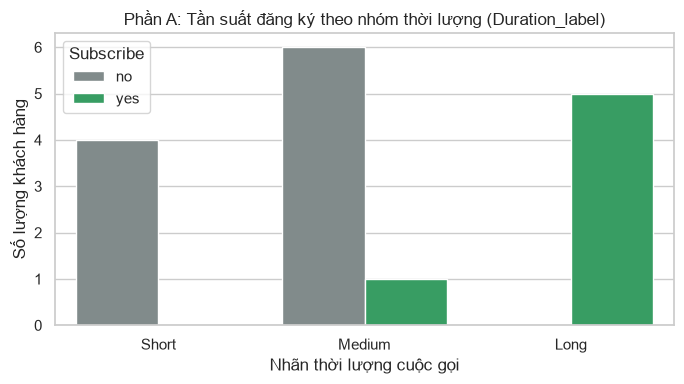

In [5]:
print(f"{STUDENT_NAME} - {MSSV}")

disc_bins_a = [0, 300, 900, 1800]
interval_labels_a = ["(0, 300]", "(300, 900]", "(900, 1800]"]
concept_labels_a = ["Short", "Medium", "Long"]

df_a_clean["Duration_interval"] = pd.cut(
    df_a_clean["Duration"], bins=disc_bins_a, labels=interval_labels_a
)
df_a_clean["Duration_label"] = pd.cut(
    df_a_clean["Duration"], bins=disc_bins_a, labels=concept_labels_a
)

print("--- Kết quả rời rạc hóa Duration (16 dòng) ---")
display(df_a_clean[["Job", "Duration", "Duration_interval", "Duration_label", "Subscribe"]])

ct_a = pd.crosstab(df_a_clean["Duration_label"], df_a_clean["Subscribe"], margins=True)
print("--- Bảng chéo Duration_label vs Subscribe ---")
display(ct_a)

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=df_a_clean, x="Duration_label", hue="Subscribe",
    order=concept_labels_a, palette={"no": "#7f8c8d", "yes": "#27ae60"}, ax=ax
)
ax.set_title("Phần A: Tần suất đăng ký theo nhóm thời lượng (Duration_label)")
ax.set_xlabel("Nhãn thời lượng cuộc gọi")
ax.set_ylabel("Số lượng khách hàng")
plt.tight_layout()
plt.show()


**Nhận xét Bước 4 (Phần A):** Rời rạc hóa làm lộ rõ mối liên hệ rất mạnh giữa thời lượng cuộc gọi và quyết định đăng ký: **100% (4/4)** cuộc gọi `Short` (`≤ 300s`) đều không đăng ký (`no`), trong khi **100% (5/5)** cuộc gọi `Long` (`> 900s`) đều đăng ký (`yes`).


### Phần A — Bước 5: Mã hóa One-hot Encoding cho các thuộc tính định tính

Để tránh gán nhầm thứ tự giả tạo cho các thuộc tính định danh (như cảnh báo ở PDF trang 13–14 khi biểu diễn `C, Q, S` thành `1, 2, 3`), ta sử dụng **`pd.get_dummies(..., dtype=int)`** cho các thuộc tính định tính đầu vào (`Job`, `Marial`, `Education`, `Default`, `Loan`), đồng thời mã hóa riêng biến mục tiêu `Subscribe` thành nhị phân (`0`: `no`, `1`: `yes`).


In [6]:
print(f"{STUDENT_NAME} - {MSSV}")

cat_cols_a = ["Job", "Marial", "Education", "Default", "Loan"]
num_cols_a = ["Duration", "Cons.price.idx"]

df_a_ohe = pd.get_dummies(
    df_a_clean[num_cols_a + cat_cols_a],
    columns=cat_cols_a,
    dtype=int,
)
df_a_ohe["Subscribe_binary"] = df_a_clean["Subscribe"].map({"no": 0, "yes": 1})

print(f"Kích thước trước One-hot (các cột gốc đầu vào + target): {(len(df_a_clean), len(num_cols_a + cat_cols_a) + 1)}")
print(f"Kích thước sau One-hot Encoding: {df_a_ohe.shape}")
print(f"Số cột mới sau khi tách One-hot ({len(cat_cols_a)} thuộc tính định tính -> {df_a_ohe.shape[1] - len(num_cols_a) - 1} cột nhị phân):")
for c in cat_cols_a:
    matched = [col for col in df_a_ohe.columns if col.startswith(f"{c}_")]
    print(f"  - {c}: {len(matched)} cột -> {matched}")

display(df_a_ohe.head(8))


Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước trước One-hot (các cột gốc đầu vào + target): (16, 8)
Kích thước sau One-hot Encoding: (16, 25)
Số cột mới sau khi tách One-hot (5 thuộc tính định tính -> 22 cột nhị phân):
  - Job: 10 cột -> ['Job_Retired', 'Job_admin.', 'Job_blue-collar', 'Job_entrepreneur', 'Job_housemaid', 'Job_management', 'Job_self-employed', 'Job_services', 'Job_technician', 'Job_unemployed']
  - Marial: 3 cột -> ['Marial_Divorced', 'Marial_Married', 'Marial_Single']
  - Education: 5 cột -> ['Education_basic.4y', 'Education_basic.9y', 'Education_high.school', 'Education_professional.course', 'Education_university.degree']
  - Default: 2 cột -> ['Default_no', 'Default_unknown']
  - Loan: 2 cột -> ['Loan_no', 'Loan_yes']


,Duration,Cons.price.idx,Job_Retired,Job_admin.,Job_blue-collar,Job_entrepreneur,Job_housemaid,Job_management,Job_self-employed,Job_services,Job_technician,Job_unemployed,Marial_Divorced,Marial_Married,Marial_Single,Education_basic.4y,Education_basic.9y,Education_high.school,Education_professional.course,Education_university.degree,Default_no,Default_unknown,Loan_no,Loan_yes,Subscribe_binary
0,261,93.994,0,0,0,0,1,0,0,0,0,0,0,1,0,1,0,0,0,0,1,0,1,0,0
1,149,93.994,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,0,1,1,0,0
2,1575,93.994,0,0,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,1,1,0,1
3,338,93.994,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,1,0,1,0,0
4,179,93.994,0,0,1,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0,1,0,0
5,1030,93.994,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,1,0,0,1,0,1,0,1
6,149,93.994,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0,0,0,1,1,0,0
7,424,93.994,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,1,0,1,1,0,0


### Phần A — Bước 6: Chuẩn hóa Min-Max Normalization về `[0, 1]`

Áp dụng công thức chuẩn hóa Min-Max ở PDF trang 15:
$$\text{new\_value} = \frac{\text{value} - \min}{\max - \min}$$
cho các thuộc tính số (`Duration` và `Cons.price.idx`) và đối chiếu kết quả với `sklearn.preprocessing.MinMaxScaler()`.


Nguyễn Phạm Bảo Khanh - 6451071033
Kiểm chứng khớp hoàn toàn với sklearn MinMaxScaler: True
Giá trị min/max sau chuẩn hóa:


,Duration_minmax,Cons.price.idx_minmax
min,0.0,0.0
max,1.0,1.0



--- Bảng đối chiếu toàn bộ 16 dòng trước và sau Min-Max Normalization ---


,Duration,Cons.price.idx,Duration_minmax,Cons.price.idx_minmax
0,261,93.994,0.0760,1.0000
1,149,93.994,0.0000,1.0000
2,1575,93.994,0.9674,1.0000
3,338,93.994,0.1282,1.0000
4,179,93.994,0.0204,1.0000
5,1030,93.994,0.5977,1.0000
6,149,93.994,0.0000,1.0000
7,424,93.994,0.1866,1.0000
8,1623,93.994,1.0000,1.0000
9,568,93.994,0.2843,1.0000


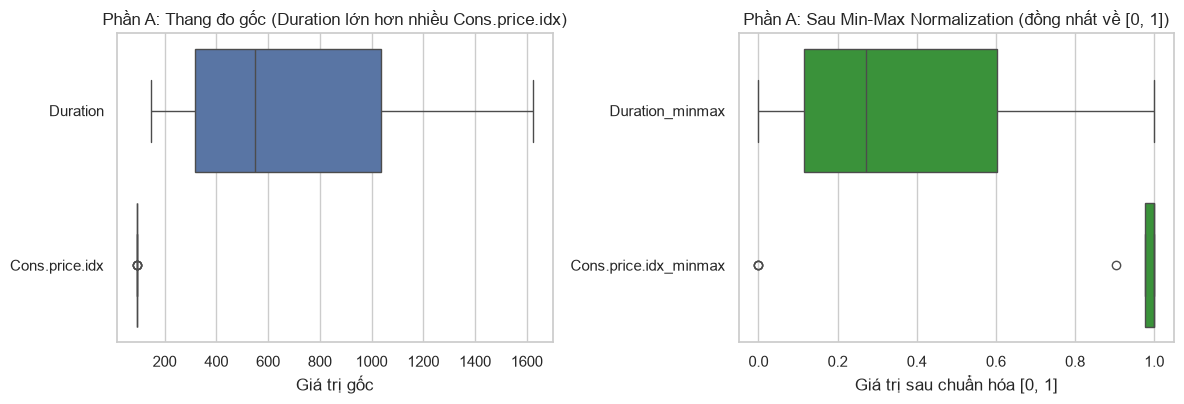

In [7]:
print(f"{STUDENT_NAME} - {MSSV}")

df_a_norm = df_a_clean[["Duration", "Cons.price.idx"]].copy()

# 1. Tính thủ công theo công thức PDF trang 15
for col in ["Duration", "Cons.price.idx"]:
    col_min = df_a_norm[col].min()
    col_max = df_a_norm[col].max()
    df_a_norm[f"{col}_minmax"] = (df_a_norm[col] - col_min) / (col_max - col_min)

# 2. Kiểm chứng bằng MinMaxScaler của scikit-learn
scaler_a = MinMaxScaler()
scaled_a = scaler_a.fit_transform(df_a_clean[["Duration", "Cons.price.idx"]])

assert np.allclose(df_a_norm[["Duration_minmax", "Cons.price.idx_minmax"]].to_numpy(), scaled_a)
print("Kiểm chứng khớp hoàn toàn với sklearn MinMaxScaler: True")
print("Giá trị min/max sau chuẩn hóa:")
display(df_a_norm[["Duration_minmax", "Cons.price.idx_minmax"]].agg(["min", "max"]))

print("\n--- Bảng đối chiếu toàn bộ 16 dòng trước và sau Min-Max Normalization ---")
display(df_a_norm.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.boxplot(data=df_a_clean[["Duration", "Cons.price.idx"]], orient="h", ax=axes[0], color="#4c72b0")
axes[0].set_title("Phần A: Thang đo gốc (Duration lớn hơn nhiều Cons.price.idx)")
axes[0].set_xlabel("Giá trị gốc")

sns.boxplot(
    data=df_a_norm[["Duration_minmax", "Cons.price.idx_minmax"]],
    orient="h", ax=axes[1], color="#2ca02c"
)
axes[1].set_title("Phần A: Sau Min-Max Normalization (đồng nhất về [0, 1])")
axes[1].set_xlabel("Giá trị sau chuẩn hóa [0, 1]")

plt.tight_layout()
plt.show()


### Tóm tắt Phần A
- Bảng mẫu 16 dòng đã được phục dựng nguyên trạng (kể cả 2 giá trị thiếu ở `Cons.price.idx` dòng index 6 và `Marial` dòng index 7, cùng 5 giá trị `'unknown'` trong `Default`).
- Sau 6 bước tiền xử lý: dữ liệu không còn `NaN`, `Duration` được khử nhiễu và rời rạc hóa thành `Short`/`Medium`/`Long`, 5 thuộc tính định tính được mã hóa thành **22 cột nhị phân** (tổng **25 cột** gồm `Duration`, `Cons.price.idx` và `Subscribe_binary`), và các biến số được đưa chuẩn về `[0, 1]`.


---
## PHẦN B: KHẢO SÁT VÀ TIỀN XỬ LÝ TẬP DỮ LIỆU `Dataset/bank/bank.csv` (4,521 DÒNG, 17 CỘT)

Theo tệp mô tả `Dataset/bank/bank-names.txt`:
- Tập `bank.csv` gồm **4,521 mẫu** (lấy ngẫu nhiên 10% từ `bank-full.csv`), **17 thuộc tính** (16 đầu vào + 1 đầu ra `y`), phân tách bằng dấu `;`.
- Lưu ý sự khác biệt lược đồ so với bảng mẫu 16 dòng ở Phần A (trích từ `bank-additional` có `Cons.price.idx`), còn `bank.csv` là bộ thuộc tính chuẩn gồm `balance`, `housing`, `day`, `month`, `campaign`, `pdays`, `previous`, `poutcome`, `y`.


### Phần B — Bước 1: Đọc dữ liệu `bank.csv`, khảo sát (`head`, `info`, `describe`) và phân loại 17 thuộc tính


Nguyễn Phạm Bảo Khanh - 6451071033
[Dataset] Đọc từ thư mục cục bộ: Dataset\bank\bank.csv
Kích thước tập dữ liệu bank.csv: (4521, 17) (4,521 dòng, 17 cột)

--- 10 dòng đầu tiên (head(10)) ---


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,unknown,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,unknown,14,may,57,2,-1,0,unknown,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no



--- Thông tin cấu trúc bảng (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        4521 non-null   int64
 1   job        4521 non-null   str  
 2   marital    4521 non-null   str  
 3   education  4521 non-null   str  
 4   default    4521 non-null   str  
 5   balance    4521 non-null   int64
 6   housing    4521 non-null   str  
 7   loan       4521 non-null   str  
 8   contact    4521 non-null   str  
 9   day        4521 non-null   int64
 10  month      4521 non-null   str  
 11  duration   4521 non-null   int64
 12  campaign   4521 non-null   int64
 13  pdays      4521 non-null   int64
 14  previous   4521 non-null   int64
 15  poutcome   4521 non-null   str  
 16  y          4521 non-null   str  
dtypes: int64(7), str(10)
memory usage: 826.8 KB

--- Thống kê mô tả các thuộc tính số (describe) ---


,age,balance,day,duration,campaign,pdays,previous
count,4521.00,4521.00,4521.00,4521.00,4521.00,4521.00,4521.00
mean,41.17,1422.66,15.92,263.96,2.79,39.77,0.54
std,10.58,3009.64,8.25,259.86,3.11,100.12,1.69
min,19.00,-3313.00,1.00,4.00,1.00,-1.00,0.00
25%,33.00,69.00,9.00,104.00,1.00,-1.00,0.00
50%,39.00,444.00,16.00,185.00,2.00,-1.00,0.00
75%,49.00,1480.00,21.00,329.00,3.00,-1.00,0.00
max,87.00,71188.00,31.00,3025.00,50.00,871.00,25.00



--- Thống kê mô tả các thuộc tính định tính ---


,job,marital,education,default,housing,loan,contact,month,poutcome,y
count,4521,4521,4521,4521,4521,4521,4521,4521,4521,4521
unique,12,3,4,2,2,2,3,12,4,2
top,management,married,secondary,no,yes,no,cellular,may,unknown,no
freq,969,2797,2306,4445,2559,3830,2896,1398,3705,4000



Phân bố biến mục tiêu y:
  - no: 4000 (88.48%)
  - yes: 521 (11.52%)


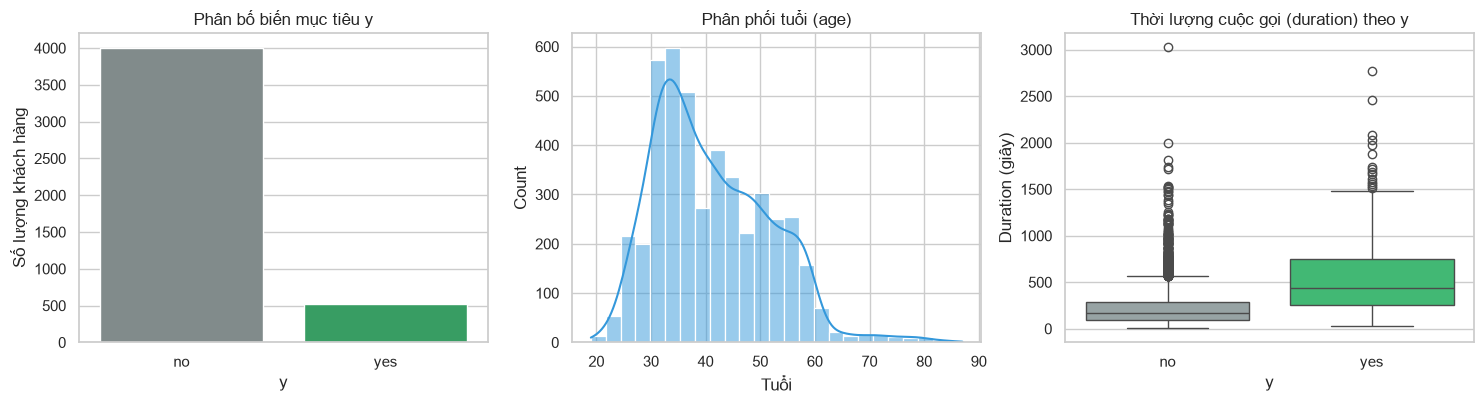

In [8]:
print(f"{STUDENT_NAME} - {MSSV}")

bank_path = get_dataset_path("bank/bank.csv")
df_b_raw = pd.read_csv(bank_path, sep=";")

print(f"Kích thước tập dữ liệu bank.csv: {df_b_raw.shape} (4,521 dòng, 17 cột)")
print("\n--- 10 dòng đầu tiên (head(10)) ---")
display(df_b_raw.head(10))

print("\n--- Thông tin cấu trúc bảng (info) ---")
df_b_raw.info()

print("\n--- Thống kê mô tả các thuộc tính số (describe) ---")
display(df_b_raw.describe().round(2))

print("\n--- Thống kê mô tả các thuộc tính định tính ---")
display(df_b_raw.describe(exclude=[np.number]))

y_counts = df_b_raw["y"].value_counts()
print("\nPhân bố biến mục tiêu y:")
for k, v in y_counts.items():
    print(f"  - {k}: {v} ({v/len(df_b_raw)*100:.2f}%)")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
sns.countplot(data=df_b_raw, x="y", hue="y", legend=False, palette={"no": "#7f8c8d", "yes": "#27ae60"}, ax=axes[0])
axes[0].set_title("Phân bố biến mục tiêu y")
axes[0].set_ylabel("Số lượng khách hàng")

sns.histplot(df_b_raw["age"], bins=25, kde=True, color="#3498db", ax=axes[1])
axes[1].set_title("Phân phối tuổi (age)")
axes[1].set_xlabel("Tuổi")

sns.boxplot(data=df_b_raw, x="y", y="duration", hue="y", legend=False, palette={"no": "#95a5a6", "yes": "#2ecc71"}, ax=axes[2])
axes[2].set_title("Thời lượng cuộc gọi (duration) theo y")
axes[2].set_ylabel("Duration (giây)")

plt.tight_layout()
plt.show()


#### Phân loại toàn bộ 17 thuộc tính trong `bank.csv` (theo lý thuyết PDF trang 1–3 & `bank-names.txt`)

| STT | Thuộc tính | Nhóm lớn | Phân loại chi tiết | Mô tả & Ghi chú |
|---:|---|---|---|---|
| 1 | `age` | Quantitative | **Ratio-scaled** | Tuổi khách hàng (19–87), có điểm 0 tự nhiên. |
| 2 | `job` | Qualitative | **Nominal** | Nghề nghiệp (12 loại gồm `'unknown'`), không có thứ tự. |
| 3 | `marital` | Qualitative | **Nominal** | Tình trạng hôn nhân (`married`, `single`, `divorced`). |
| 4 | `education` | Qualitative | **Ordinal** | Trình độ học vấn (`primary` < `secondary` < `tertiary`, kèm `'unknown'`). |
| 5 | `default` | Qualitative | **Binary asymmetric** | Có nợ xấu mặc định không (`no`: 4,445, `yes`: 76). |
| 6 | `balance` | Quantitative | **Ratio-scaled** | Số dư tài khoản bình quân năm (euro; nhận giá trị âm `-3,313` đến `71,188` do thấu chi, gốc `0` euro thật sự). |
| 7 | `housing` | Qualitative | **Binary asymmetric** | Có vay mua nhà hay không (`yes`: 2,559, `no`: 1,962). |
| 8 | `loan` | Qualitative | **Binary asymmetric** | Có khoản vay cá nhân hay không (`no`: 3,830, `yes`: 691). |
| 9 | `contact` | Qualitative | **Nominal** | Kênh liên hệ (`cellular`, `telephone`, `unknown`). |
| 10 | `day` | Quantitative | **Interval-scaled** | Ngày trong tháng (`1..31`) của lần liên hệ cuối; không có mốc 0 tuyệt đối. |
| 11 | `month` | Qualitative | **Nominal** *(chu kỳ lịch)* | Tháng liên hệ cuối (`jan`..`dec`); dạng danh mục thời điểm trong năm. |
| 12 | `duration` | Quantitative | **Ratio-scaled** | Thời lượng cuộc gọi cuối (4–3,025 giây), có giá trị 0 thật sự. |
| 13 | `campaign` | Quantitative | **Ratio-scaled** | Số lần liên hệ trong chiến dịch hiện tại (`1..50`). |
| 14 | `pdays` | Quantitative | **Ratio-scaled** *(có mã `-1`)* | Số ngày kể từ lần liên hệ ở chiến dịch trước (`-1` là mã quy ước *chưa từng liên hệ*). |
| 15 | `previous` | Quantitative | **Ratio-scaled** | Số lần liên hệ trước chiến dịch hiện tại (`0..25`). |
| 16 | `poutcome` | Qualitative | **Nominal** | Kết quả chiến dịch trước (`unknown`, `failure`, `other`, `success`). |
| 17 | `y` | Qualitative | **Binary asymmetric** *(Target)* | Có đăng ký gửi tiền có kỳ hạn hay không (`no`: 4,000, `yes`: 521). |


### Phần B — Bước 2: Kiểm tra và xử lý dữ liệu bị thiếu (`NaN`, `'unknown'`, và `pdays == -1`)

Mặc dù `bank.csv` không có giá trị `NaN` tường minh, tập dữ liệu tồn tại **thiếu ẩn (implicit missing)** dưới hai dạng:
1. Nhãn **`'unknown'`** trong 4 cột phân loại: `job` (`38`), `education` (`187`), `contact` (`1,324`), `poutcome` (`3,705`).
2. Giá trị **`pdays == -1`** (`3,705` dòng, chiếm `81.95%`), mã hóa việc khách hàng chưa từng được liên hệ ở chiến dịch trước.

**Chiến lược xử lý:**
- `job` (`0.84%`) và `education` (`4.14%`): tỷ lệ thiếu nhỏ (< 5%) -> thay `'unknown'` bằng **mode** (`'management'` và `'secondary'`).
- `contact` (`29.29%`) và `poutcome` (`81.95%`): tỷ lệ thiếu cao -> **giữ nguyên nhãn `'unknown'`** như một giá trị phân loại hợp lệ (theo PDF trang 14) để không làm sai lệch phân phối.
- `pdays == -1`: tách thêm biến cờ nhị phân **`previously_contacted`** (`0` nếu `pdays == -1`, `1` nếu `pdays != -1`) và tạo cột **`pdays_clean`** thay `-1` bằng `0` để loại bỏ mã âm khi tính toán/chuẩn hóa số học, đồng thời thống kê riêng thời gian chờ thật trên 816 khách hàng đã từng liên hệ.


Nguyễn Phạm Bảo Khanh - 6451071033
Số lượng NaN tường minh trên từng cột:
{'age': 0, 'job': 0, 'marital': 0, 'education': 0, 'default': 0, 'balance': 0, 'housing': 0, 'loan': 0, 'contact': 0, 'day': 0, 'month': 0, 'duration': 0, 'campaign': 0, 'pdays': 0, 'previous': 0, 'poutcome': 0, 'y': 0}

--- Thống kê nhãn 'unknown' trong bank.csv ---


,Cột,Số lượng 'unknown',Tỷ lệ (%),Mode (nhóm đã biết)
0,job,38,0.84,management
1,education,187,4.14,secondary
2,contact,1324,29.29,cellular
3,poutcome,3705,81.95,failure



Số dòng pdays == -1: 3705 (81.95%)
Khớp 100% với previous == 0: True | Khớp 100% với poutcome == 'unknown': True
Thống kê pdays trên nhóm ĐÃ từng liên hệ (pdays != -1):


count    816.00
mean     224.87
std      117.20
min        1.00
25%      136.00
50%      189.00
75%      330.00
max      871.00
Name: pdays, dtype: float64

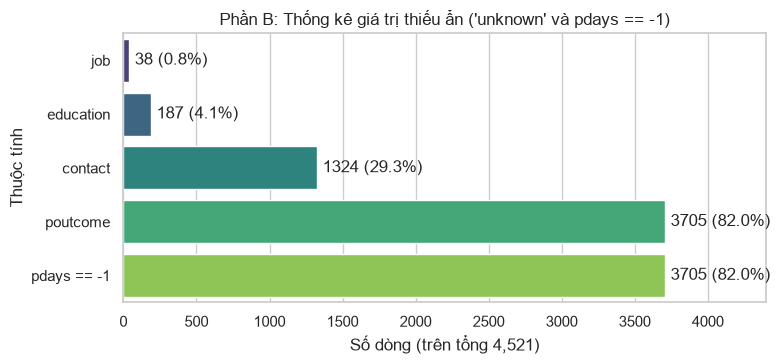


--- Kiểm tra sau xử lý missing ẩn ---
Số 'unknown' còn lại ở job: 0
Số 'unknown' còn lại ở education: 0
Giữ 'unknown' ở contact: 1324 | poutcome: 3705
Phân bố previously_contacted: {0: 3705, 1: 816}
Tổng NaN toàn bảng df_b_clean: 0


In [9]:
print(f"{STUDENT_NAME} - {MSSV}")

print("Số lượng NaN tường minh trên từng cột:")
print(df_b_raw.isnull().sum().to_dict())

# Thống kê 'unknown' ở các cột định tính
unknown_rows = []
for col in df_b_raw.select_dtypes(exclude=[np.number]).columns:
    cnt = int((df_b_raw[col] == "unknown").sum())
    if cnt > 0:
        known_mode = df_b_raw.loc[df_b_raw[col] != "unknown", col].mode()[0]
        unknown_rows.append({
            "Cột": col,
            "Số lượng 'unknown'": cnt,
            "Tỷ lệ (%)": round(cnt / len(df_b_raw) * 100, 2),
            "Mode (nhóm đã biết)": known_mode,
        })

df_unknown_stats = pd.DataFrame(unknown_rows)
print("\n--- Thống kê nhãn 'unknown' trong bank.csv ---")
display(df_unknown_stats)

# Kiểm tra cấu trúc pdays == -1
pdays_neg1_mask = df_b_raw["pdays"] == -1
same_prev0 = (pdays_neg1_mask == (df_b_raw["previous"] == 0)).all()
same_pout_unk = (pdays_neg1_mask == (df_b_raw["poutcome"] == "unknown")).all()
print(f"\nSố dòng pdays == -1: {pdays_neg1_mask.sum()} ({pdays_neg1_mask.mean()*100:.2f}%)")
print(f"Khớp 100% với previous == 0: {same_prev0} | Khớp 100% với poutcome == 'unknown': {same_pout_unk}")
print("Thống kê pdays trên nhóm ĐÃ từng liên hệ (pdays != -1):")
display(df_b_raw.loc[~pdays_neg1_mask, "pdays"].describe().round(2))

# Trực quan hóa mức độ missing ẩn
plot_missing = df_unknown_stats[["Cột", "Số lượng 'unknown'"]].rename(
    columns={"Cột": "Thuộc tính", "Số lượng 'unknown'": "Số lượng"}
)
plot_missing = pd.concat([
    plot_missing,
    pd.DataFrame([{"Thuộc tính": "pdays == -1", "Số lượng": int(pdays_neg1_mask.sum())}])
], ignore_index=True)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(data=plot_missing, y="Thuộc tính", x="Số lượng", hue="Thuộc tính", legend=False, palette="viridis", ax=ax)
ax.set_title("Phần B: Thống kê giá trị thiếu ẩn ('unknown' và pdays == -1)")
ax.set_xlabel("Số dòng (trên tổng 4,521)")
for i, v in enumerate(plot_missing["Số lượng"]):
    ax.text(v + 40, i, f"{v} ({v/len(df_b_raw)*100:.1f}%)", va="center")
ax.set_xlim(0, 4400)
plt.tight_layout()
plt.show()

# Thực hiện xử lý tạo df_b_clean
df_b_clean = df_b_raw.copy()
job_mode = df_b_clean.loc[df_b_clean["job"] != "unknown", "job"].mode()[0]
edu_mode = df_b_clean.loc[df_b_clean["education"] != "unknown", "education"].mode()[0]

df_b_clean["job"] = df_b_clean["job"].replace("unknown", job_mode)
df_b_clean["education"] = df_b_clean["education"].replace("unknown", edu_mode)
df_b_clean["previously_contacted"] = (df_b_clean["pdays"] != -1).astype(int)
df_b_clean["pdays_clean"] = df_b_clean["pdays"].replace(-1, 0)

print("\n--- Kiểm tra sau xử lý missing ẩn ---")
print("Số 'unknown' còn lại ở job:", (df_b_clean["job"] == "unknown").sum())
print("Số 'unknown' còn lại ở education:", (df_b_clean["education"] == "unknown").sum())
print("Giữ 'unknown' ở contact:", (df_b_clean["contact"] == "unknown").sum(),
      "| poutcome:", (df_b_clean["poutcome"] == "unknown").sum())
print("Phân bố previously_contacted:", df_b_clean["previously_contacted"].value_counts().to_dict())
print("Tổng NaN toàn bảng df_b_clean:", int(df_b_clean.isnull().sum().sum()))


### Phần B — Bước 3: Khử nhiễu `age` và `duration` bằng Binning và Smoothing + Trực quan hóa

Thực hiện làm trơn theo **trung bình giỏ (smoothing by bin mean)** cho cả hai thuộc tính số quan trọng:
- **`age`** (min `19`, max `87`): chia giỏ đều độ rộng 10 tuổi `[10, 20, 30, 40, 50, 60, 70, 80, 90]` (8 giỏ, mọi giỏ đều có mẫu).
- **`duration`** (min `4`, max `3025`): do phân phối lệch phải mạnh với một số cuộc gọi kéo dài > 2,000s, ta thực hiện và so sánh **Equal-width Binning** (`[0, 500, 1000, 1500, 2000, 2500, 3500]`) với **Equal-frequency Binning** (`pd.qcut(..., q=5)`).


Nguyễn Phạm Bảo Khanh - 6451071033
--- Bảng Binning & Smoothing cho age ---


,age_bin,So_luong,Min,Max,Bin_Mean
0,"(10, 20]",7,19,20,19.43
1,"(20, 30]",625,21,30,27.55
2,"(30, 40]",1800,31,40,35.08
3,"(40, 50]",1162,41,50,45.29
4,"(50, 60]",800,51,60,55.19
5,"(60, 70]",73,61,70,64.67
6,"(70, 80]",46,71,80,75.39
7,"(80, 90]",8,81,87,83.75


--- Bảng Equal-width Binning cho duration ---


,duration_ew_bin,So_luong,Min,Max,Bin_Mean
0,"(0, 500]",3927,4,500,183.62
1,"(500, 1000]",487,501,998,676.86
2,"(1000, 1500]",82,1006,1484,1182.85
3,"(1500, 2000]",20,1504,1994,1665.65
4,"(2000, 2500]",3,2029,2456,2190.67
5,"(2500, 3500]",2,2769,3025,2897.00


--- Bảng Equal-frequency Binning (q=5) cho duration ---


,duration_ef_bin,So_luong,Min,Max,Bin_Mean
0,"(3.999, 89.0]",917,4,89,53.45
1,"(89.0, 149.0]",900,90,149,119.43
2,"(149.0, 226.0]",898,150,226,186.37
3,"(226.0, 383.0]",904,227,383,291.91
4,"(383.0, 3025.0]",902,384,3025,671.42


Std age: gốc=10.58 -> smoothed=10.22
Std duration: gốc=259.86 -> EW=231.34 | EF=218.25


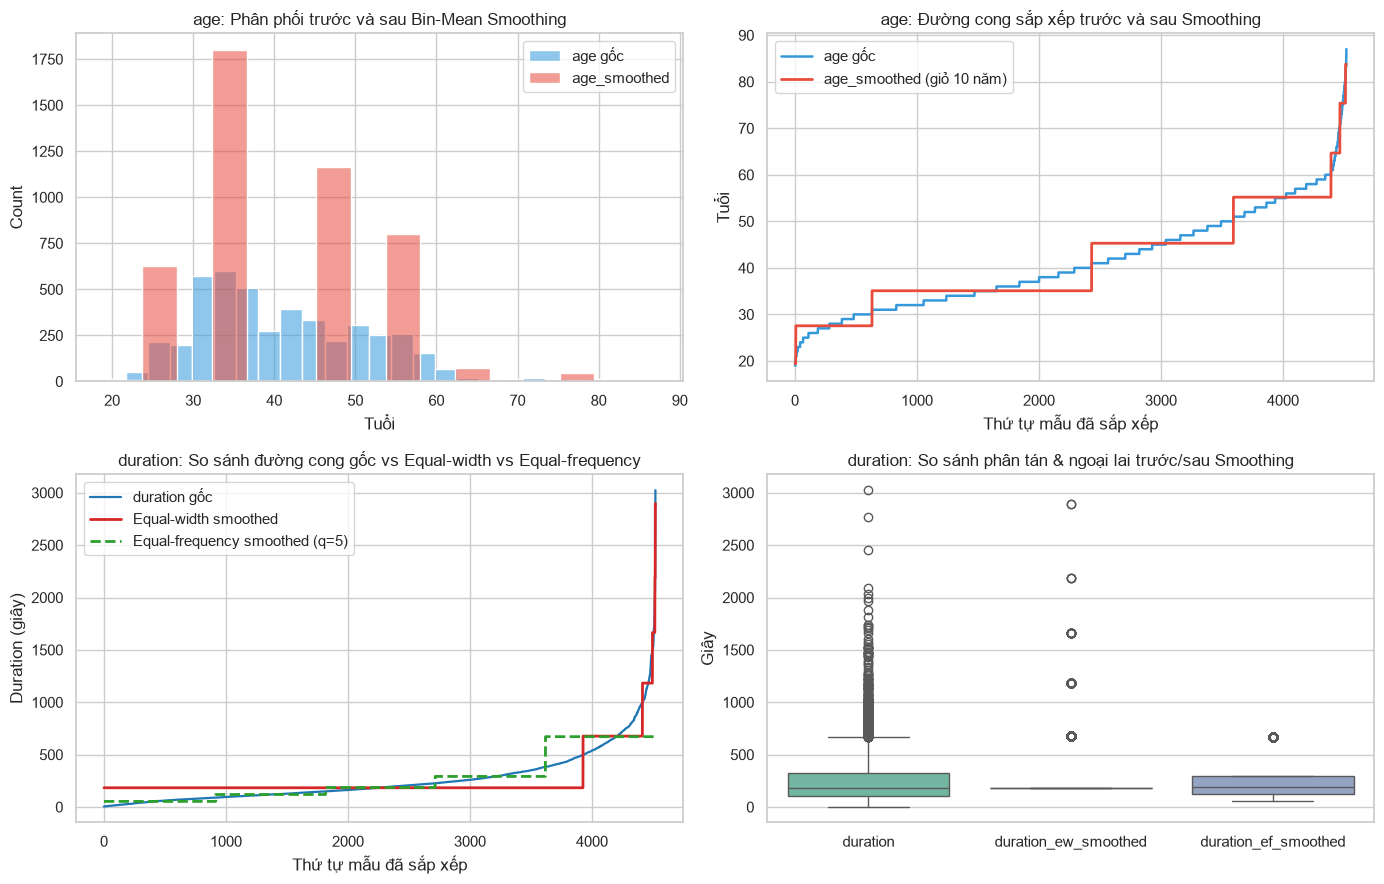

In [10]:
print(f"{STUDENT_NAME} - {MSSV}")

# 1. Binning & Smoothing cho age (Equal-width, width=10)
age_bins = [10, 20, 30, 40, 50, 60, 70, 80, 90]
df_b_clean["age_bin"] = pd.cut(df_b_clean["age"], bins=age_bins)
df_b_clean["age_smoothed"] = (
    df_b_clean.groupby("age_bin", observed=False)["age"]
    .transform("mean")
    .round(2)
)

age_bin_summary = (
    df_b_clean.groupby("age_bin", observed=False)["age"]
    .agg(So_luong="count", Min="min", Max="max", Bin_Mean="mean")
    .reset_index()
)
print("--- Bảng Binning & Smoothing cho age ---")
display(age_bin_summary.round(2))

# 2. Binning & Smoothing cho duration (so sánh Equal-width vs Equal-frequency)
dur_ew_bins = [0, 500, 1000, 1500, 2000, 2500, 3500]
df_b_clean["duration_ew_bin"] = pd.cut(df_b_clean["duration"], bins=dur_ew_bins)
df_b_clean["duration_ew_smoothed"] = (
    df_b_clean.groupby("duration_ew_bin", observed=False)["duration"]
    .transform("mean")
    .round(2)
)

df_b_clean["duration_ef_bin"] = pd.qcut(df_b_clean["duration"], q=5)
df_b_clean["duration_ef_smoothed"] = (
    df_b_clean.groupby("duration_ef_bin", observed=False)["duration"]
    .transform("mean")
    .round(2)
)

print("--- Bảng Equal-width Binning cho duration ---")
display(
    df_b_clean.groupby("duration_ew_bin", observed=False)["duration"]
    .agg(So_luong="count", Min="min", Max="max", Bin_Mean="mean")
    .reset_index()
    .round(2)
)

print("--- Bảng Equal-frequency Binning (q=5) cho duration ---")
display(
    df_b_clean.groupby("duration_ef_bin", observed=False)["duration"]
    .agg(So_luong="count", Min="min", Max="max", Bin_Mean="mean")
    .reset_index()
    .round(2)
)

print(
    f"Std age: gốc={df_b_clean['age'].std():.2f} -> smoothed={df_b_clean['age_smoothed'].std():.2f}"
)
print(
    f"Std duration: gốc={df_b_clean['duration'].std():.2f} -> "
    f"EW={df_b_clean['duration_ew_smoothed'].std():.2f} | EF={df_b_clean['duration_ef_smoothed'].std():.2f}"
)

# Trực quan hóa so sánh trước và sau làm trơn
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# age histogram trước vs sau
sns.histplot(df_b_clean["age"], bins=25, alpha=0.55, color="#3498db", label="age gốc", ax=axes[0, 0])
sns.histplot(df_b_clean["age_smoothed"], bins=15, alpha=0.55, color="#e74c3c", label="age_smoothed", ax=axes[0, 0])
axes[0, 0].set_title("age: Phân phối trước và sau Bin-Mean Smoothing")
axes[0, 0].set_xlabel("Tuổi")
axes[0, 0].legend()

# age sorted curve
age_sorted = df_b_clean[["age", "age_smoothed"]].sort_values("age").reset_index(drop=True)
axes[0, 1].plot(age_sorted.index, age_sorted["age"], linewidth=1.8, label="age gốc", color="#3498db")
axes[0, 1].plot(age_sorted.index, age_sorted["age_smoothed"], linewidth=2.0, label="age_smoothed (giỏ 10 năm)", color="#e74c3c")
axes[0, 1].set_title("age: Đường cong sắp xếp trước và sau Smoothing")
axes[0, 1].set_xlabel("Thứ tự mẫu đã sắp xếp")
axes[0, 1].set_ylabel("Tuổi")
axes[0, 1].legend()

# duration sorted curve
dur_sorted = df_b_clean[["duration", "duration_ew_smoothed", "duration_ef_smoothed"]].sort_values("duration").reset_index(drop=True)
axes[1, 0].plot(dur_sorted.index, dur_sorted["duration"], linewidth=1.6, label="duration gốc", color="#1f77b4")
axes[1, 0].plot(dur_sorted.index, dur_sorted["duration_ew_smoothed"], linewidth=2.0, label="Equal-width smoothed", color="#d62728")
axes[1, 0].plot(dur_sorted.index, dur_sorted["duration_ef_smoothed"], linewidth=2.0, linestyle="--", label="Equal-frequency smoothed (q=5)", color="#2ca02c")
axes[1, 0].set_title("duration: So sánh đường cong gốc vs Equal-width vs Equal-frequency")
axes[1, 0].set_xlabel("Thứ tự mẫu đã sắp xếp")
axes[1, 0].set_ylabel("Duration (giây)")
axes[1, 0].legend()

# duration boxplot comparison
dur_melt = df_b_clean[["duration", "duration_ew_smoothed", "duration_ef_smoothed"]].melt(
    var_name="Phiên bản", value_name="Giây"
)
sns.boxplot(data=dur_melt, x="Phiên bản", y="Giây", hue="Phiên bản", legend=False, palette="Set2", ax=axes[1, 1])
axes[1, 1].set_title("duration: So sánh phân tán & ngoại lai trước/sau Smoothing")
axes[1, 1].set_xlabel("")

plt.tight_layout()
plt.show()


**Nhận xét Bước 3 (Phần B):**
- Với `age`, phân phối khá cân đối quanh 30–50 tuổi nên chia giỏ đều độ rộng 10 năm cho tất cả 8 giỏ đều có đủ quan sát và làm trơn mượt mà (độ lệch chuẩn giảm nhẹ từ `10.58` xuống `10.22`).
- Với `duration` bị lệch phải rất mạnh (`3,927` mẫu nằm trong `(0, 500]` nhưng chỉ có `5` mẫu trên `2,000s`), **Equal-width** làm nổi bật vùng đuôi dài nhưng tạo các giỏ rất thưa ở cuối, còn **Equal-frequency (`q=5`)** cân bằng ~904 mẫu/giỏ và gom các giá trị cực đại ở đuôi về trung bình nhóm lớn nhất (`671.42s`), giúp giảm độ lệch chuẩn từ `259.86s` xuống `231.34s` (Equal-width) và `218.25s` (Equal-frequency).


### Phần B — Bước 4: Rời rạc hóa `age` và `duration` theo khoảng giá trị và nhãn khái niệm

- **`age`**:
  - Khoảng giá trị: `(18, 30]`, `(30, 45]`, `(45, 60]`, `(60, 90]`
  - Nhãn khái niệm: `Youth`, `Adult`, `Middle-aged`, `Senior`
- **`duration`**:
  - Khoảng giá trị: `(0, 180]`, `(180, 600]`, `(600, 3500]`
  - Nhãn khái niệm: `Short` (≤ 3 phút), `Medium` (3–10 phút), `Long` (> 10 phút)


Nguyễn Phạm Bảo Khanh - 6451071033
--- Thống kê rời rạc hóa thuộc tính age ---


,age_interval,age_group,So_khach_hang,So_dang_ky,Ty_le_yes_pct
0,"(18, 30]",Youth,632,90,14.24
1,"(30, 45]",Adult,2408,236,9.80
2,"(45, 60]",Middle-aged,1354,147,10.86
3,"(60, 90]",Senior,127,48,37.80


--- Thống kê rời rạc hóa thuộc tính duration ---


,duration_interval,duration_group,So_khach_hang,So_dang_ky,Ty_le_yes_pct
0,"(0, 180]",Short,2212,56,2.53
1,"(180, 600]",Medium,1887,275,14.57
2,"(600, 3500]",Long,422,190,45.02


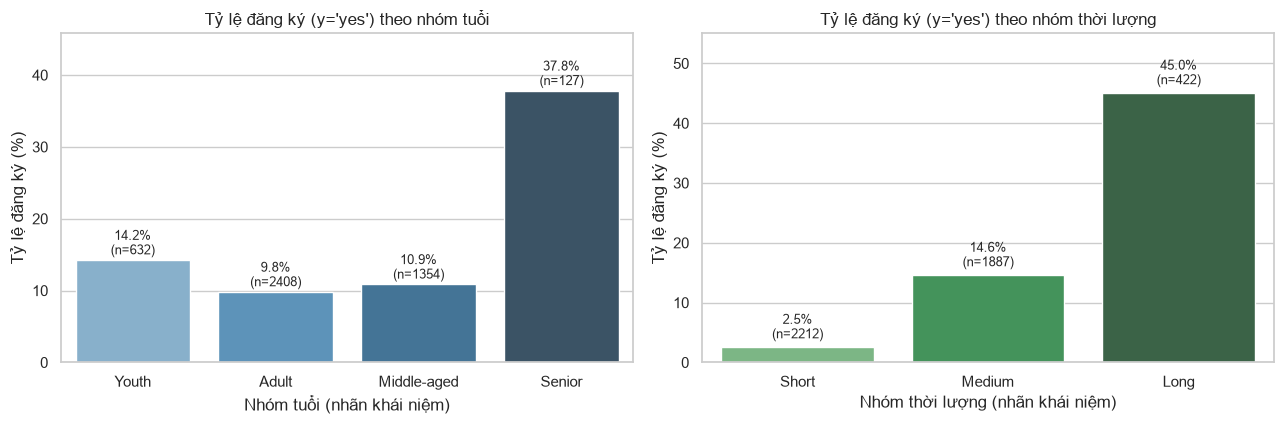

In [11]:
print(f"{STUDENT_NAME} - {MSSV}")

age_disc_bins = [18, 30, 45, 60, 90]
age_intervals = ["(18, 30]", "(30, 45]", "(45, 60]", "(60, 90]"]
age_concepts = ["Youth", "Adult", "Middle-aged", "Senior"]

df_b_clean["age_interval"] = pd.cut(df_b_clean["age"], bins=age_disc_bins, labels=age_intervals)
df_b_clean["age_group"] = pd.cut(df_b_clean["age"], bins=age_disc_bins, labels=age_concepts)

dur_disc_bins = [0, 180, 600, 3500]
dur_intervals = ["(0, 180]", "(180, 600]", "(600, 3500]"]
dur_concepts = ["Short", "Medium", "Long"]

df_b_clean["duration_interval"] = pd.cut(df_b_clean["duration"], bins=dur_disc_bins, labels=dur_intervals)
df_b_clean["duration_group"] = pd.cut(df_b_clean["duration"], bins=dur_disc_bins, labels=dur_concepts)

df_b_clean["y_binary"] = (df_b_clean["y"] == "yes").astype(int)

age_disc_stats = (
    df_b_clean.groupby(["age_interval", "age_group"], observed=True)
    .agg(So_khach_hang=("y_binary", "count"), So_dang_ky=("y_binary", "sum"), Ty_le_yes_pct=("y_binary", lambda s: s.mean() * 100))
    .reset_index()
    .round(2)
)
dur_disc_stats = (
    df_b_clean.groupby(["duration_interval", "duration_group"], observed=True)
    .agg(So_khach_hang=("y_binary", "count"), So_dang_ky=("y_binary", "sum"), Ty_le_yes_pct=("y_binary", lambda s: s.mean() * 100))
    .reset_index()
    .round(2)
)

print("--- Thống kê rời rạc hóa thuộc tính age ---")
display(age_disc_stats)
print("--- Thống kê rời rạc hóa thuộc tính duration ---")
display(dur_disc_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))

ax1 = axes[0]
sns.barplot(data=age_disc_stats, x="age_group", y="Ty_le_yes_pct", hue="age_group", dodge=False, legend=False, palette="Blues_d", ax=ax1)
ax1.set_title("Tỷ lệ đăng ký (y='yes') theo nhóm tuổi")
ax1.set_xlabel("Nhóm tuổi (nhãn khái niệm)")
ax1.set_ylabel("Tỷ lệ đăng ký (%)")
for i, row in age_disc_stats.iterrows():
    ax1.text(i, row["Ty_le_yes_pct"] + 0.8, f"{row['Ty_le_yes_pct']:.1f}%\n(n={row['So_khach_hang']})", ha="center", fontsize=9)
ax1.set_ylim(0, age_disc_stats["Ty_le_yes_pct"].max() + 8)

ax2 = axes[1]
sns.barplot(data=dur_disc_stats, x="duration_group", y="Ty_le_yes_pct", hue="duration_group", dodge=False, legend=False, palette="Greens_d", ax=ax2)
ax2.set_title("Tỷ lệ đăng ký (y='yes') theo nhóm thời lượng")
ax2.set_xlabel("Nhóm thời lượng (nhãn khái niệm)")
ax2.set_ylabel("Tỷ lệ đăng ký (%)")
for i, row in dur_disc_stats.iterrows():
    ax2.text(i, row["Ty_le_yes_pct"] + 1.5, f"{row['Ty_le_yes_pct']:.1f}%\n(n={row['So_khach_hang']})", ha="center", fontsize=9)
ax2.set_ylim(0, dur_disc_stats["Ty_le_yes_pct"].max() + 10)

plt.tight_layout()
plt.show()


**Nhận xét Bước 4 (Phần B):**
- Nhóm tuổi `Senior` (> 60 tuổi) dù chỉ có `127` khách hàng nhưng đạt tỷ lệ đăng ký cao nhất (**`37.80%`**), tiếp theo là `Youth` (`14.24%`), cao hơn hẳn nhóm `Adult` (`9.80%`) và `Middle-aged` (`10.86%`).
- Nhóm thời lượng cuộc gọi `Long` (> 600s) có tỷ lệ đăng ký đạt **`45.02%`**, cao gấp gần 18 lần so với nhóm `Short` (**`2.53%`**) và hơn 3 lần nhóm `Medium` (**`14.57%`**).


### Phần B — Bước 5: Mã hóa One-hot Encoding cho các thuộc tính định tính

Áp dụng `pd.get_dummies(..., dtype=int)` cho toàn bộ 9 thuộc tính định tính đầu vào (`job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `poutcome`) trên tập dữ liệu đã làm sạch `df_b_clean`, giữ kèm cột cờ `previously_contacted` và mã hóa nhị phân biến mục tiêu `y` (`y_binary`).


In [12]:
print(f"{STUDENT_NAME} - {MSSV}")

cat_cols_b = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
num_cols_b_base = ["age", "balance", "day", "duration", "campaign", "pdays_clean", "previous", "previously_contacted"]

df_b_ohe = pd.get_dummies(
    df_b_clean[num_cols_b_base + cat_cols_b],
    columns=cat_cols_b,
    dtype=int,
)
df_b_ohe["y_binary"] = df_b_clean["y_binary"]

print(f"Kích thước bảng gốc ban đầu: {df_b_raw.shape}")
print(f"Kích thước sau One-hot Encoding (+ y_binary): {df_b_ohe.shape}")
print("\nChi tiết số cột sinh ra cho từng thuộc tính định tính:")
for col in cat_cols_b:
    dummy_cols = [c for c in df_b_ohe.columns if c.startswith(f"{col}_")]
    print(f"  - {col:<10}: {len(dummy_cols):2d} cột -> {dummy_cols}")

print("\nKiểm tra toàn bộ cột one-hot đều là kiểu số nguyên và không có NaN:")
print("Tổng NaN trong df_b_ohe:", int(df_b_ohe.isnull().sum().sum()))
display(df_b_ohe.head(5))


Nguyễn Phạm Bảo Khanh - 6451071033
Kích thước bảng gốc ban đầu: (4521, 17)
Kích thước sau One-hot Encoding (+ y_binary): (4521, 51)

Chi tiết số cột sinh ra cho từng thuộc tính định tính:
  - job       : 11 cột -> ['job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed']
  - marital   :  3 cột -> ['marital_divorced', 'marital_married', 'marital_single']
  - education :  3 cột -> ['education_primary', 'education_secondary', 'education_tertiary']
  - default   :  2 cột -> ['default_no', 'default_yes']
  - housing   :  2 cột -> ['housing_no', 'housing_yes']
  - loan      :  2 cột -> ['loan_no', 'loan_yes']
  - contact   :  3 cột -> ['contact_cellular', 'contact_telephone', 'contact_unknown']
  - month     : 12 cột -> ['month_apr', 'month_aug', 'month_dec', 'month_feb', 'month_jan', 'month_jul', 'month_jun', 'month_mar', 'month_may', 'month_nov', 'month_oct'

,age,balance,day,duration,campaign,pdays_clean,previous,previously_contacted,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,education_primary,education_secondary,education_tertiary,default_no,default_yes,housing_no,housing_yes,loan_no,loan_yes,contact_cellular,contact_telephone,contact_unknown,month_apr,month_aug,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep,poutcome_failure,poutcome_other,poutcome_success,poutcome_unknown,y_binary
0,30,1787,19,79,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,1,0,0,1,0,1,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,1,0
1,33,4789,11,220,1,339,4,1,0,0,0,0,0,0,0,1,0,0,0,0,1,0,0,1,0,1,0,0,1,0,1,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
2,35,1350,16,185,1,330,1,1,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,1,0,0,1,1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,30,1476,3,199,4,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,1,1,0,0,1,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0
4,59,0,5,226,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0


### Phần B — Bước 6: Chuẩn hóa Min-Max Normalization về `[0, 1]`

Áp dụng công thức chuẩn hóa Min-Max (PDF trang 15) cho các thuộc tính số của `bank.csv` (`age`, `balance`, `day`, `duration`, `campaign`, `pdays`, `previous`, cùng `pdays_clean`), đưa mọi biến số về miền `[0, 1]` để tránh các biến có biên độ lớn như `balance` (`-3,313` đến `71,188`) hay `duration` (`4` đến `3,025`) áp đảo các thuật toán khoảng cách (`k-NN`, `k-Means`, `SVM`, `Neural Networks`), đồng thời kiểm chứng với `sklearn.preprocessing.MinMaxScaler()`.


Nguyễn Phạm Bảo Khanh - 6451071033
Kiểm chứng khớp hoàn toàn với sklearn MinMaxScaler: True

--- Thống kê mô tả trước khi chuẩn hóa ---


,age,balance,day,duration,campaign,pdays,previous,pdays_clean
min,19.00,-3313.00,1.00,4.00,1.00,-1.00,0.00,0.00
25%,33.00,69.00,9.00,104.00,1.00,-1.00,0.00,0.00
50%,39.00,444.00,16.00,185.00,2.00,-1.00,0.00,0.00
75%,49.00,1480.00,21.00,329.00,3.00,-1.00,0.00,0.00
max,87.00,71188.00,31.00,3025.00,50.00,871.00,25.00,871.00
mean,41.17,1422.66,15.92,263.96,2.79,39.77,0.54,40.59
std,10.58,3009.64,8.25,259.86,3.11,100.12,1.69,99.79



--- Thống kê mô tả sau Min-Max Normalization (về đúng [0, 1]) ---


,age,balance,day,duration,campaign,pdays,previous,pdays_clean
min,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
25%,0.2059,0.0454,0.2667,0.0331,0.0000,0.0000,0.0000,0.0000
50%,0.2941,0.0504,0.5000,0.0599,0.0204,0.0000,0.0000,0.0000
75%,0.4412,0.0643,0.6667,0.1076,0.0408,0.0000,0.0000,0.0000
max,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
mean,0.3260,0.0636,0.4972,0.0861,0.0366,0.0468,0.0217,0.0466
std,0.1555,0.0404,0.2749,0.0860,0.0635,0.1148,0.0677,0.1146


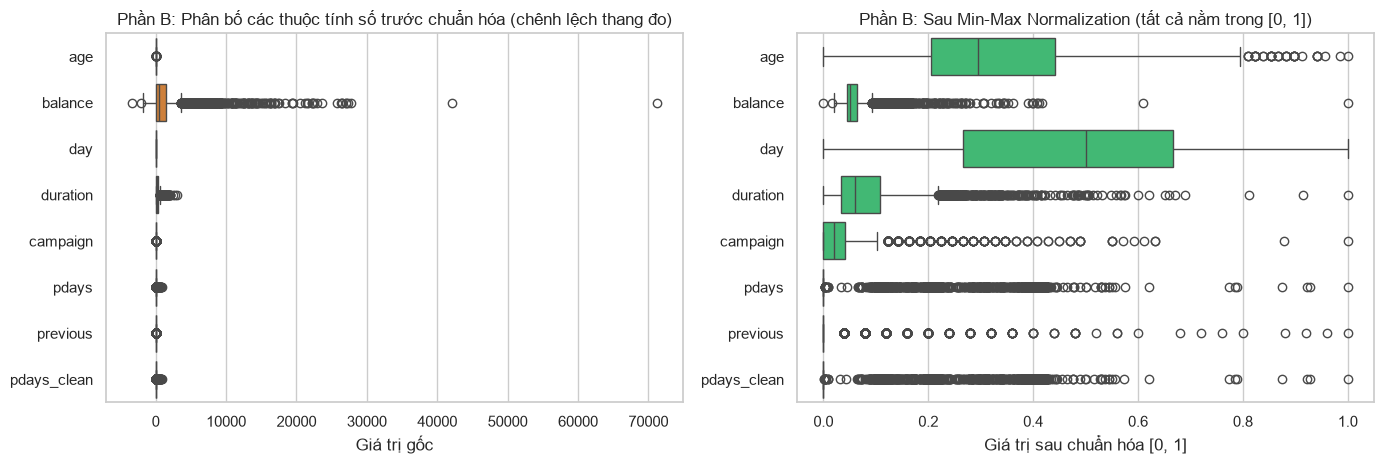

In [13]:
print(f"{STUDENT_NAME} - {MSSV}")

num_cols_norm_b = ["age", "balance", "day", "duration", "campaign", "pdays", "previous", "pdays_clean"]

# 1. Tính theo công thức thủ công (PDF trang 15)
df_b_minmax = pd.DataFrame(index=df_b_clean.index)
for col in num_cols_norm_b:
    c_min = df_b_clean[col].min()
    c_max = df_b_clean[col].max()
    df_b_minmax[col] = (df_b_clean[col] - c_min) / (c_max - c_min)

# 2. Kiểm chứng với MinMaxScaler
scaler_b = MinMaxScaler()
scaled_b = scaler_b.fit_transform(df_b_clean[num_cols_norm_b])
assert np.allclose(df_b_minmax.to_numpy(), scaled_b)
print("Kiểm chứng khớp hoàn toàn với sklearn MinMaxScaler: True")

print("\n--- Thống kê mô tả trước khi chuẩn hóa ---")
display(df_b_clean[num_cols_norm_b].describe().loc[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(2))

print("\n--- Thống kê mô tả sau Min-Max Normalization (về đúng [0, 1]) ---")
display(df_b_minmax.describe().loc[["min", "25%", "50%", "75%", "max", "mean", "std"]].round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.boxplot(data=df_b_clean[num_cols_norm_b], orient="h", ax=axes[0], color="#e67e22")
axes[0].set_title("Phần B: Phân bố các thuộc tính số trước chuẩn hóa (chênh lệch thang đo)")
axes[0].set_xlabel("Giá trị gốc")

sns.boxplot(data=df_b_minmax, orient="h", ax=axes[1], color="#2ecc71")
axes[1].set_title("Phần B: Sau Min-Max Normalization (tất cả nằm trong [0, 1])")
axes[1].set_xlabel("Giá trị sau chuẩn hóa [0, 1]")

plt.tight_layout()
plt.show()


### Tổng kết toàn bộ quy trình tiền xử lý (Phần A & Phần B)
- **Phần A (16 dòng mẫu PDF trang 28–29)**: xử lý `NaN` ở `Cons.price.idx` (`93.994`) và `Marial` (`'Married'`), xử lý/phân tích `'unknown'` ở `Default`, làm trơn `Duration`, rời rạc hóa `Short`/`Medium`/`Long`, One-hot encoding 5 biến định tính, và chuẩn hóa Min-Max về `[0, 1]`.
- **Phần B (`Dataset/bank/bank.csv`, 4,521 dòng × 17 cột)**: khảo sát và phân loại đủ 17 thuộc tính; xử lý `'unknown'` ở `job`/`education` bằng mode và giữ `'unknown'` ở `contact`/`poutcome`; tách cờ `previously_contacted` cho `pdays == -1`; làm trơn `age` và `duration` (đối chiếu Equal-width vs Equal-frequency); rời rạc hóa thành `Youth`/`Adult`/`Middle-aged`/`Senior` và `Short`/`Medium`/`Long`; One-hot encoding tạo bảng sạch sẵn sàng cho huấn luyện mô hình; và chuẩn hóa Min-Max toàn bộ biến số về `[0, 1]`.
